<a href="https://colab.research.google.com/github/sohyun223/ai-application-2026/blob/main/Week06_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6주차 실습 — 첫 주행: 베이스 미세조정 · ONNX 배포 · 폐루프 평가
**AI Application · 스마트모빌리티학과 · 2026-10-07 · 파이프라인 ③ 학습 + ④ 배포 + ⑤ 평가**

| 셀 | 내용 |
|---|---|
| 1 | 베이스 모델 성적표 — 공개 / 미공개 / 트랙별 |
| 2 | 실패 프레임 분석 — 어디서 왜 이탈하나 |
| 3 | scratch vs finetune — 같은 데이터, 같은 에폭 |
| 4 | ONNX 내보내기 + torch 일치 검증 + 지연 |
| 5 | 비교표 (expert / base / scratch / finetune) — 공개·미공개 |
| 6 | 트랙별 성적과 점수 분해 |
| 7 | (선택) 동결 미세조정 + 시드 3개 평균 |

**준비물**: `tinytrack.py`, `models/base_pilotnet.pt`·`.onnx` (배포 저장소 `e2e_starter/models/`), Drive 의 `week05/my_dataset_v1.npz` (없으면 v0 에서 즉석 생성). CPU 로 전체 10분 안팎 (학습 2회 + 폐루프 평가 20회)."

**약어**: ONNX = Open Neural Network Exchange(프레임워크 공통 모델 파일) · onnxruntime = 그 실행 라이브러리 · npz = numpy 압축 배열 파일 · MSE/MAE = 평균제곱/평균절대오차 · CSV = 쉼표 구분 텍스트 표 · atol = 허용 절대오차 · PilotNet = NVIDIA 의 E2E 조향 CNN(Bojarski 외 2016, arXiv:1604.07316)

In [ ]:
# ============ 0. 준비 (재접속 시 여기부터) ============
import importlib.util, subprocess, sys, os, time, json
for pkg in ["onnx", "onnxruntime", "pandas"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
import numpy as np, matplotlib.pyplot as plt, pandas as pd, torch
from pathlib import Path
try:
    import tinytrack as tt
except ImportError:
    from google.colab import files
    print("tinytrack.py 를 업로드하세요"); files.upload(); import tinytrack as tt
try:
    from google.colab import drive
    drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive/AIApp")
except Exception:
    ROOT = Path("./outputs")
SAVE_DIR = ROOT / "week06"; SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 베이스 모델 파일: 같은 폴더의 models/ 또는 업로드
MODELS = Path("models") if Path("models/base_pilotnet.pt").exists() else Path(".")
if not (MODELS / "base_pilotnet.pt").exists():
    try:
        from google.colab import files
        print("base_pilotnet.pt 와 base_pilotnet.onnx 를 업로드하세요 (e2e_starter/models/)"); files.upload()
    except ImportError:
        raise SystemExit("models/base_pilotnet.pt 가 필요합니다")
BASE_PT, BASE_ONNX = MODELS / "base_pilotnet.pt", MODELS / "base_pilotnet.onnx"

# 데이터: v1 (과제 2) → 없으면 v0 → 없으면 재생성
v1_path, v0_path = ROOT / "week05" / "my_dataset_v1.npz", ROOT / "week04" / "my_dataset_v0.npz"
if v1_path.exists():
    v1 = tt.load_npz(v1_path); print("v1 로드")
elif v0_path.exists():
    v1 = tt.rebalance(tt.load_npz(v0_path)); print("v0 → rebalance")
else:
    print("데이터가 없어 재생성합니다 (약 20초)")
    v1 = tt.rebalance(tt.merge(*[tt.collect(tt.ExpertPolicy(), tt.Track.preset(n), 500, seed=10 * ord(n) + k, noise_inject=ni)
                                 for n in "ABC" for k, ni in enumerate([0.0, 0.4, 0.8])]))
tr, va = tt.split_by_run(v1, 0.2, seed=0)
torch.manual_seed(0); np.random.seed(0)
PUBLIC, HIDDEN = ["A", "B", "C"], [tt.Track.random(101), tt.Track.random(202)]
print("tinytrack", tt.__version__, "| 학습", len(tr["steers"]), "검증", len(va["steers"]), "| 저장:", SAVE_DIR)

tinytrack.py 를 업로드하세요


Saving tinytrack.py to tinytrack.py
Mounted at /content/drive
base_pilotnet.pt 와 base_pilotnet.onnx 를 업로드하세요 (e2e_starter/models/)


Saving base_pilotnet.onnx to base_pilotnet.onnx
Saving base_pilotnet.pt to base_pilotnet.pt
v1 로드
tinytrack 0.3.1 | 학습 2257 검증 591 | 저장: /content/drive/MyDrive/AIApp/week06


## 1. 베이스 모델 성적표
교수가 사전학습한 `base_pilotnet.onnx` 를 여러분의 평가 프로토콜(공개 A/B/C + 미공개 랜덤 2개, 외란 포함)로 채점합니다. 이 숫자가 오늘의 **출발점**입니다.

먼저 **외란 없이** 한 번, **외란 포함**으로 한 번 — 이 베이스는 깨끗한 전문가 데이터만으로(복구 데이터·시프트 증강 없이) 학습됐습니다. 두 숫자의 차이가 곧 5주차의 '복구 부재' 병입니다.

In [ ]:
base_pol = tt.OnnxPolicy(BASE_ONNX)
t0 = time.time()
no_dist = tt.evaluate(base_pol, PUBLIC, disturb=None)
print(f"외란 없음 : score={no_dist['score']:.1f}  completion={no_dist['completion']:.2f}  mean|d|={no_dist['mean_abs_d']:.3f}   ← 깨끗한 트랙에선 거의 완벽")
base_pub = tt.evaluate(base_pol, PUBLIC, verbose=True)
print(f"외란 포함 : score={base_pub['score']:.1f}  completion={base_pub['completion']:.2f}  mean|d|={base_pub['mean_abs_d']:.3f}   ← 밀리면 돌아오지 못한다")
base_hid = tt.evaluate(base_pol, HIDDEN, verbose=True)
print(f"\n베이스: 공개 score={base_pub['score']:.1f} (comp {base_pub['completion']:.2f}) | 미공개 score={base_hid['score']:.1f} (comp {base_hid['completion']:.2f})  ({time.time()-t0:.0f}s)")
mae_base, _, _ = tt.offline_mae(base_pol, va, n=300)
print(f"베이스의 내 검증셋 오프라인 MAE = {mae_base:.3f}")
rep_path = MODELS / "pretrain_report.json"
if rep_path.exists():
    rep = json.load(open(rep_path)); print("교수 보고서:", {k: round(rep["base_pilotnet"][k]["score"], 1) for k in ("public", "hidden", "random_style")})

외란 없음 : score=99.5  completion=1.00  mean|d|=0.005   ← 깨끗한 트랙에선 거의 완벽
  A: completion=0.25 off=1.00 |d|=0.081
  B: completion=0.17 off=1.00 |d|=0.077
  C: completion=0.18 off=1.00 |d|=0.093
외란 포함 : score=9.3  completion=0.20  mean|d|=0.084   ← 밀리면 돌아오지 못한다
  rand101: completion=0.24 off=1.00 |d|=0.084
  rand202: completion=0.18 off=1.00 |d|=0.095

베이스: 공개 score=9.3 (comp 0.20) | 미공개 score=9.5 (comp 0.21)  (37s)
베이스의 내 검증셋 오프라인 MAE = 0.317


## 2. 실패 프레임 분석 — 어디서 왜
가장 어려운 트랙 C 에서 베이스를 굴려 이탈 시점 직전의 `(d, ψ, κ, steer)` 를 봅니다. 이탈하지 않았다면 |d| 가 가장 컸던 구간을 봅니다.

[base] 이탈 @ step 92 | 직전 30스텝 |d| 평균 0.173, 곡률 +0.250, 마지막 조향 -0.12, 헤딩 -0.81


/tmp/ipykernel_496/1045648680.py:19: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
/tmp/ipykernel_496/1045648680.py:19: UserWarning: Glyph 47001 (\N{HANGUL SYLLABLE RAEG}) missing from font(s) DejaVu Sans.
  plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
/tmp/ipykernel_496/1045648680.py:19: UserWarning: Glyph 44452 (\N{HANGUL SYLLABLE GWE}) missing from font(s) DejaVu Sans.
  plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
/tmp/ipykernel_496/1045648680.py:19: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPy

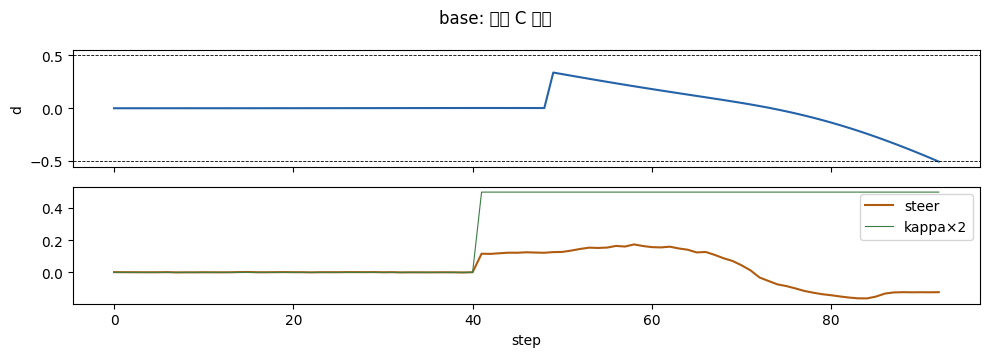

/content/tinytrack.py:453: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 46608 (\N{HANGUL SYLLABLE DDO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 45716 (\N{HANGUL SYLLABLE NEUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51204 (\N{HANGUL SYLLABL

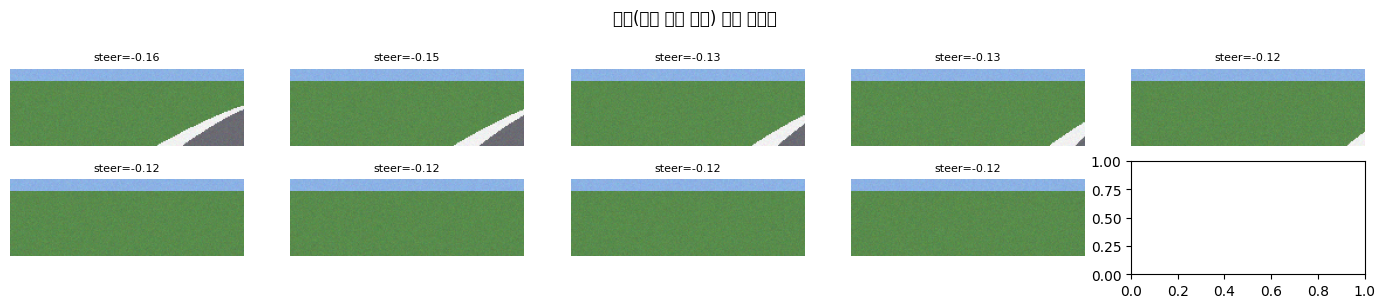

In [ ]:
def rollout_log(pol, track, seed=0, max_steps=1500):
    env = tt.Env(track, disturb=tt.DEFAULT_DISTURB, seed=seed, max_steps=max_steps)
    obs = env.reset(seed=seed); log, frames = [], []
    for t in range(max_steps):
        a = pol(obs, env.state); frames.append(obs)
        obs, r, term, trunc, info = env.step(a)
        log.append((t, info["d"], info["psi"], info["kappa"], a))
        if term or trunc: break
    return np.array(log), frames, bool(term)

def analyze(log, frames, term, name=""):
    end = len(log) - 1 if term else int(np.argmax(np.abs(log[:, 1])))
    w = log[max(0, end - 30):end + 1]
    print(f"[{name}] {'이탈' if term else '완주'} @ step {int(log[end,0])} | 직전 30스텝 |d| 평균 {np.abs(w[:,1]).mean():.3f}, "
          f"곡률 {w[-1,3]:+.3f}, 마지막 조향 {w[-1,4]:+.2f}, 헤딩 {w[-1,2]:+.2f}")
    fig, ax = plt.subplots(2, 1, figsize=(10, 3.6), sharex=True)
    ax[0].plot(log[:, 1], color="#2563A8"); ax[0].axhline(0.5, ls="--", c="k", lw=.6); ax[0].axhline(-0.5, ls="--", c="k", lw=.6); ax[0].set_ylabel("d")
    ax[1].plot(log[:, 4], color="#B05C10", label="steer"); ax[1].plot(log[:, 3] * 2, color="#3A7D44", lw=.8, label="kappa×2"); ax[1].legend(); ax[1].set_xlabel("step")
    plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
    idx = list(range(max(0, end - 8), end + 1))
    tt.show_frames(np.array(frames)[idx], log[idx, 4], n=len(idx), title="이탈(또는 최대 이탈) 직전 프레임"); plt.show()

log_b, fr_b, term_b = rollout_log(base_pol, tt.Track.preset("C"))
analyze(log_b, fr_b, term_b, "base")

## 3. scratch vs finetune — 같은 데이터, 같은 에폭
- **scratch**: 무작위 초기화, lr 1e-3
- **finetune**: 베이스에서 시작, lr 3e-4 (1/3)
둘 다 증강 켜고 4에폭. 학습 곡선을 나란히 봅니다.

epoch 1/4  train=0.15028  val=0.20991  (22s)
epoch 2/4  train=0.09646  val=0.07256  (41s)
epoch 3/4  train=0.03859  val=0.04508  (59s)
epoch 4/4  train=0.03062  val=0.04450  (79s)
--- scratch 91s ---
epoch 1/4  train=0.06307  val=0.05109  (22s)
epoch 2/4  train=0.01904  val=0.01428  (42s)
epoch 3/4  train=0.01033  val=0.02751  (61s)
epoch 4/4  train=0.00868  val=0.02860  (80s)
--- finetune 80s ---


/tmp/ipykernel_496/1386519413.py:17: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "curves_v1.png", dpi=120); plt.show()
/tmp/ipykernel_496/1386519413.py:17: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "curves_v1.png", dpi=120); plt.show()
/tmp/ipykernel_496/1386519413.py:17: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "curves_v1.png", dpi=120); plt.show()
/tmp/ipykernel_496/1386519413.py:17: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "curves_v1.png", dpi=120); plt.show()
/tmp/ipykernel_496/1386519413.py:17: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "curves_v1.p

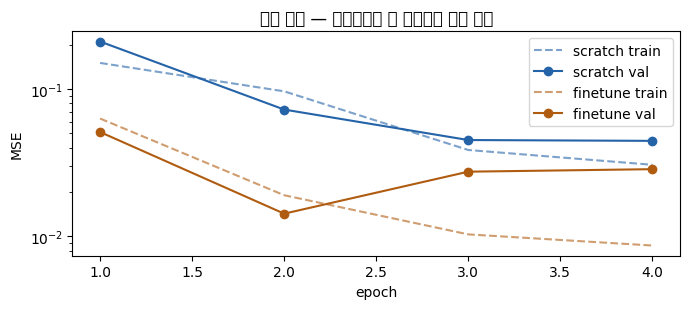

In [ ]:
EPOCHS = 4
aug = tt.make_augment(seed=0)
t0 = time.time()
m_scratch = tt.make_model()
h_scratch = tt.train_bc(m_scratch, tr, va, epochs=EPOCHS, lr=1e-3, augment=aug, save_path=SAVE_DIR / "scratch_v1.pt", verbose=True)
print(f"--- scratch {time.time()-t0:.0f}s ---")
t0 = time.time()
m_ft = tt.load_model(BASE_PT)
h_ft = tt.train_bc(m_ft, tr, va, epochs=EPOCHS, lr=3e-4, augment=aug, save_path=SAVE_DIR / "my_policy_v1.pt", verbose=True)
print(f"--- finetune {time.time()-t0:.0f}s ---")

plt.figure(figsize=(7, 3.2))
for h, name, c in [(h_scratch, "scratch", "#2563A8"), (h_ft, "finetune", "#B05C10")]:
    plt.plot(range(1, EPOCHS+1), h["train"], "--", color=c, alpha=.6, label=f"{name} train")
    plt.plot(range(1, EPOCHS+1), h["val"], "o-", color=c, label=f"{name} val")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.title("학습 곡선 — 미세조정은 첫 에폭부터 낮게 시작")
plt.tight_layout(); plt.savefig(SAVE_DIR / "curves_v1.png", dpi=120); plt.show()

## 4. ONNX 내보내기 + 일치 검증 + 지연
베스트 체크포인트(train_bc 가 복원해 둠)에서 내보내고, torch 출력과 onnx 출력이 같은지 배치 1·8 로 확인합니다.

In [ ]:
def check_parity(model, onnx_path, images):
    import onnxruntime as ort
    sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
    model = model.cpu().eval(); worst = 0.0
    for n in (1, 8):
        x = np.concatenate([tt.preprocess(im) for im in images[:n]])
        with torch.no_grad(): y_t = model(torch.from_numpy(x)).numpy()
        y_o = sess.run(None, {"image": x})[0]
        worst = max(worst, float(np.abs(y_t - y_o).max()))
    return worst

paths = {}
for name, m in [("scratch_v1", m_scratch), ("my_policy_v1", m_ft)]:
    p = tt.export_onnx(m, SAVE_DIR / f"{name}.onnx"); paths[name] = p
    diff = check_parity(m, p, va["images"])
    print(f"{name}: torch-onnx 최대 차이 {diff:.2e}  {'OK' if diff < 1e-4 else 'MISMATCH!'}  ({os.path.getsize(p)//1024} KB)")
pol_ft = tt.OnnxPolicy(paths["my_policy_v1"]); pol_ft(va["images"][0])
t0 = time.time(); [pol_ft(va["images"][i]) for i in range(200)]; ms = (time.time()-t0)/200*1000
print(f"추론 지연 {ms:.2f} ms/프레임 → 30 fps 예산의 {33/ms:.0f}배 여유")

scratch_v1: torch-onnx 최대 차이 1.64e-07  OK  (988 KB)
my_policy_v1: torch-onnx 최대 차이 1.19e-07  OK  (988 KB)
추론 지연 1.16 ms/프레임 → 30 fps 예산의 28배 여유


## 5. 비교표 — expert / base / scratch / finetune, 공개·미공개
이 표가 실험 기록의 뼈대입니다. CSV 로 저장해 GitHub 개인 저장소에 커밋하세요.

In [ ]:
policies = {"expert": tt.ExpertPolicy(), "base": base_pol,
            "scratch": tt.OnnxPolicy(paths["scratch_v1"]), "finetune": pol_ft}
rows = []; t0 = time.time()
for name, pol in policies.items():
    pub = tt.evaluate(pol, PUBLIC); hid = tt.evaluate(pol, HIDDEN)
    mae = tt.offline_mae(pol, va, n=300)[0] if name != "expert" else 0.0
    rows.append(dict(policy=name, offline_mae=mae, pub_score=pub["score"], pub_comp=pub["completion"], pub_off=pub["offtrack_rate"],
                     hid_score=hid["score"], hid_comp=hid["completion"], mean_abs_d=pub["mean_abs_d"]))
df = pd.DataFrame(rows).round(3)
df.insert(1, "data", "v1"); df.insert(2, "epochs", EPOCHS); df.insert(3, "lr", ["-", "-", 1e-3, 3e-4])
print(df.to_string(index=False)); df.to_csv(SAVE_DIR / "compare_v1.csv", index=False)
print(f"\n({time.time()-t0:.0f}s) 저장: {SAVE_DIR/'compare_v1.csv'}")

  policy data  epochs      lr  offline_mae  pub_score  pub_comp  pub_off  hid_score  hid_comp  mean_abs_d
  expert   v1       4       -        0.000     89.824     1.000      0.0     89.836     1.000       0.102
    base   v1       4       -        0.317      9.295     0.203      1.0      9.531     0.209       0.084
 scratch   v1       4   0.001        0.134     10.125     0.224      1.0     10.477     0.232       0.098
finetune   v1       4  0.0003        0.084     83.777     1.000      0.0     84.110     1.000       0.162

(74s) 저장: /content/drive/MyDrive/AIApp/week06/compare_v1.csv


## 6. 트랙별 성적과 점수 분해
어느 트랙에서 깎였는지, 그리고 score 의 세 인자(completion · offtrack · |d|) 중 무엇이 문제인지.

         completion  offtrack_rate  mean_abs_d   steps
A               1.0            0.0       0.170  1500.0
B               1.0            0.0       0.153  1500.0
C               1.0            0.0       0.164  1500.0
rand101         1.0            0.0       0.156  1500.0
rand202         1.0            0.0       0.162  1500.0

공개 score 분해: 100 × 1.00(completion) × 1.00(1−0.5·offtrack) × 0.84(1−0.5·|d|/0.5) = 83.8
우선순위: completion < 1 이면 '완주'(복구·코너링 데이터)가 먼저, 완주했다면 |d| (부드러움)
[finetune] 완주 @ step 802 | 직전 30스텝 |d| 평균 0.148, 곡률 +0.250, 마지막 조향 -0.70, 헤딩 +0.03


/tmp/ipykernel_496/1045648680.py:19: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
/tmp/ipykernel_496/1045648680.py:19: UserWarning: Glyph 47001 (\N{HANGUL SYLLABLE RAEG}) missing from font(s) DejaVu Sans.
  plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
/tmp/ipykernel_496/1045648680.py:19: UserWarning: Glyph 44452 (\N{HANGUL SYLLABLE GWE}) missing from font(s) DejaVu Sans.
  plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
/tmp/ipykernel_496/1045648680.py:19: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.suptitle(f"{name}: 트랙 C 궤적"); plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPy

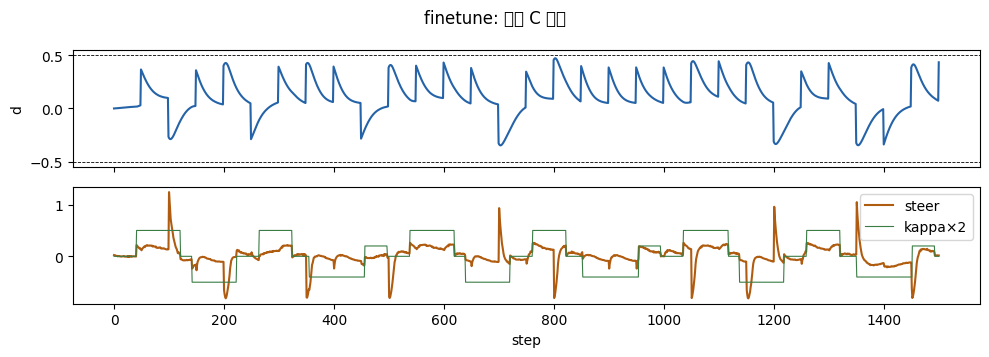

/content/tinytrack.py:453: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 46608 (\N{HANGUL SYLLABLE DDO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 45716 (\N{HANGUL SYLLABLE NEUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51204 (\N{HANGUL SYLLABL

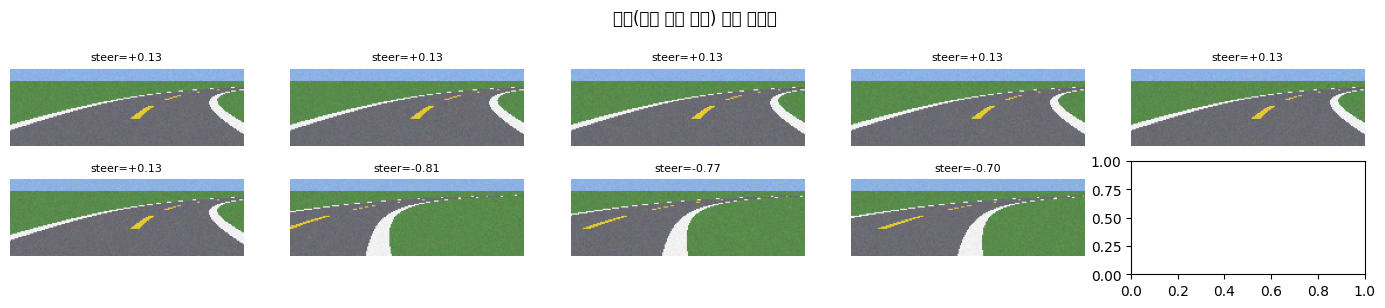

In [ ]:
ft_pub = tt.evaluate(pol_ft, PUBLIC); ft_hid = tt.evaluate(pol_ft, HIDDEN)
per = {**ft_pub["per_track"], **ft_hid["per_track"]}
print(pd.DataFrame(per).T.round(3).to_string())
c, o, m = ft_pub["completion"], ft_pub["offtrack_rate"], ft_pub["mean_abs_d"]
print(f"\n공개 score 분해: 100 × {c:.2f}(completion) × {1-0.5*o:.2f}(1−0.5·offtrack) × {1-0.5*min(m/0.5,1):.2f}(1−0.5·|d|/0.5) = {ft_pub['score']:.1f}")
print("우선순위: completion < 1 이면 '완주'(복구·코너링 데이터)가 먼저, 완주했다면 |d| (부드러움)")
log_f, fr_f, term_f = rollout_log(pol_ft, tt.Track.preset("C"))
analyze(log_f, fr_f, term_f, "finetune")
json.dump(dict(public=ft_pub, hidden=ft_hid), open(SAVE_DIR / "my_policy_v1_result.json", "w"), indent=1)

## 7. (선택) 동결 미세조정 + 시드 3개 평균
conv 를 동결하고 헤드만 학습하면 어떻게 되는지, 그리고 한 번의 score 가 얼마나 흔들리는지 (시드 3개).

In [ ]:
m_fr = tt.load_model(BASE_PT)
h_fr = tt.train_bc(m_fr, tr, va, epochs=3, lr=1e-3, augment=aug, freeze_features=True, save_path=SAVE_DIR / "freeze_v1.pt", verbose=False)
pol_fr = tt.OnnxPolicy(tt.export_onnx(m_fr, SAVE_DIR / "freeze_v1.onnx"))
print(f"freeze: val_mse={min(h_fr['val']):.4f}")
for name, pol in [("finetune", pol_ft), ("freeze", pol_fr)]:
    scores = [tt.evaluate(pol, PUBLIC, seed=s)["score"] for s in (0, 1, 2)]
    print(f"{name:9s} 공개 score 시드별 {np.round(scores,1)} → 평균 {np.mean(scores):.1f} ± {np.std(scores):.1f}")

freeze: val_mse=0.0866
finetune  공개 score 시드별 [83.8 84.4 83.8] → 평균 84.0 ± 0.3
freeze    공개 score 시드별 [34.1 24.3 10.4] → 평균 22.9 ± 9.7


## 정리 · 제출
- 베이스 → 미세조정: 학습률 1/3, 짧은 에폭, 베스트 체크포인트. 곡선은 첫 에폭부터 낮게 시작.
- ONNX 계약: `image (N,3,66,200) 0~1 → steer`. torch 와 일치(1e-4) 검증 후 배포.
- 비교표(공개·미공개)와 점수 분해가 '다음에 무엇을 할지'를 정한다. 실패 프레임의 (d, ψ, κ, a) 가 7주차 DAgger 의 입력.

**리더보드 제출**: `week06/my_policy_v1.onnx` 를 GitHub 개인 저장소에 push 하고 Mattermost 에 링크 (수요일 밤 게시).
**과제 3** (`과제3_미세조정배포.ipynb`): 위 절차를 직접 구현. 마감 10/13(화) 23:59.